In [ ]:
##Notebook 05 — Degradation mapping + results
##This is the final notebook. It produces your actual research outputs:

###Degradation risk map — spatial map of risk scores across the Mara
###Vegetation trajectory map — recovering / stable / degrading / collapsed
###Attention visualization — which timesteps the model attends to per location
###UMAP embedding map — vegetation clusters in learned embedding space
###Folium dashboard — interactive map combining all outputs

In [1]:
import torch
import numpy as np
import pickle
import sys
import json
import zarr
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

sys.path.append('C:/vegformer')
from models.vegformer import build_vegformer

PROCESSED_DIR = Path('C:/vegformer/data/processed')
PATCHES_DIR   = Path('C:/vegformer/data/patches')
CKPT_DIR      = Path('C:/vegformer/checkpoints')
OUTPUT_DIR    = Path('C:/vegformer/outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'maps').mkdir(exist_ok=True)
(OUTPUT_DIR / 'dashboards').mkdir(exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load checkpoint
model = build_vegformer({
    'n_bands':        14,
    'n_climate_vars': 4,
    'd_model':        384,
    'n_heads':        8,
    'n_layers':       4,
    'n_veg_classes':  8,
    'n_deg_classes':  4,
    'dropout':        0.1,
    'max_seq_len':    137,
}).to(device)

ckpt = torch.load(str(CKPT_DIR / 'msm_best.pt'), map_location=device)
model.load_state_dict(ckpt['model_state'])
model.eval()

# Load all patches
with open(PATCHES_DIR / 'train_patches.pkl', 'rb') as f:
    train_patches = pickle.load(f)
with open(PATCHES_DIR / 'val_patches.pkl', 'rb') as f:
    val_patches = pickle.load(f)
with open(PATCHES_DIR / 'test_patches.pkl', 'rb') as f:
    test_patches = pickle.load(f)

all_patches = train_patches + val_patches + test_patches
print(f"Checkpoint loaded — epoch {ckpt['epoch']+1}, loss {ckpt['loss']:.4f}")
print(f"Total patches: {len(all_patches)}")
print(f"Device: {device}")
print(f"Ready for degradation mapping")

C:\vegformer\models\vegformer.py:120: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal_attn = nn.TransformerEncoder(encoder_layer, num_layers=2)
C:\vegformer\models\vegformer.py:148: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
C:\vegformer\models\vegformer.py:296: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


Checkpoint loaded — epoch 24, loss 0.1041
Total patches: 240
Device: cpu
Ready for degradation mapping


In [ ]:
####Run inference across all patches to build the spatial maps

In [2]:
# Run inference on all 240 patches
print("Running inference on all patches...")

results = {
    'risk_scores':   [],
    'veg_types':     [],
    'degradation':   [],
    'embeddings':    [],
    'sar_attn':      [],
    'positions':     [],
}

class InferenceDataset(Dataset):
    def __init__(self, patches):
        self.patches = patches
    def __len__(self):
        return len(self.patches)
    def __getitem__(self, idx):
        p = self.patches[idx]
        # Use full time series for inference
        s2 = p['s2'] if p['s2'].shape[0] > 14 else p['s2']
        return {
            's2':          torch.tensor(p['s2'],          dtype=torch.float32),
            's1':          torch.tensor(p['s1'],          dtype=torch.float32),
            'chirps':      torch.tensor(p['chirps'],      dtype=torch.float32),
            'julian_days': torch.tensor(p['julian_days'], dtype=torch.float32),
            'row':         p['row'],
            'col':         p['col'],
        }

inf_ds     = InferenceDataset(all_patches)
inf_loader = DataLoader(inf_ds, batch_size=8, shuffle=False, num_workers=0)

model.eval()
with torch.no_grad():
    for batch in inf_loader:
        model_input = {
            'sar':     batch['s1'].mean(dim=(-2,-1)).to(device),
            'optical': batch['s2'].mean(dim=(-2,-1)).to(device),
            'climate': batch['chirps'].to(device),
            'dates':   batch['julian_days'].to(device),
        }
        out = model(model_input)

        results['risk_scores'].append(
            out['risk_score'].cpu().numpy())
        results['veg_types'].append(
            out['veg_type'].argmax(dim=-1).cpu().numpy())
        results['degradation'].append(
            out['degradation'].argmax(dim=-1).cpu().numpy())
        results['embeddings'].append(
            out['embeddings'].cpu().numpy())
        results['sar_attn'].append(
            out['sar_attn'].mean(dim=1).cpu().numpy())
        results['positions'].append(
            np.stack([batch['row'], batch['col']], axis=1))

# Concatenate all results
for k in results:
    results[k] = np.concatenate(results[k], axis=0)

print(f"Inference complete:")
print(f"  Patches:     {len(results['risk_scores'])}")
print(f"  Risk scores: min={results['risk_scores'].min():.3f}  "
      f"max={results['risk_scores'].max():.3f}  "
      f"mean={results['risk_scores'].mean():.3f}")
print(f"  Veg types:   {np.unique(results['veg_types'], return_counts=True)}")
print(f"  Degradation: {np.unique(results['degradation'], return_counts=True)}")

Running inference on all patches...


ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 109 and the array at index 10 has size 14

In [ ]:
####The patches have different temporal lengths (train=109, val/test=14). Fix by using only the temporal mean for inference 
###we don't need the full sequence for mapping:

In [3]:
results = {
    'risk_scores':   [],
    'veg_types':     [],
    'degradation':   [],
    'embeddings':    [],
    'positions':     [],
}

model.eval()
with torch.no_grad():
    for p in all_patches:
        model_input = {
            'sar':     torch.tensor(p['s1'], dtype=torch.float32)
                           .mean(dim=(-2,-1)).unsqueeze(0).to(device),
            'optical': torch.tensor(p['s2'], dtype=torch.float32)
                           .mean(dim=(-2,-1)).unsqueeze(0).to(device),
            'climate': torch.tensor(p['chirps'], dtype=torch.float32)
                           .unsqueeze(0).to(device),
            'dates':   torch.tensor(p['julian_days'], dtype=torch.float32)
                           .unsqueeze(0).to(device),
        }
        out = model(model_input)

        results['risk_scores'].append(out['risk_score'].cpu().numpy()[0,0])
        results['veg_types'].append(out['veg_type'].argmax(dim=-1).cpu().numpy()[0])
        results['degradation'].append(out['degradation'].argmax(dim=-1).cpu().numpy()[0])
        results['embeddings'].append(out['embeddings'].cpu().numpy()[0])
        results['positions'].append([p['row'], p['col']])

results['risk_scores']  = np.array(results['risk_scores'])
results['veg_types']    = np.array(results['veg_types'])
results['degradation']  = np.array(results['degradation'])
results['embeddings']   = np.array(results['embeddings'])
results['positions']    = np.array(results['positions'])

print(f"Inference complete:")
print(f"  Patches:     {len(results['risk_scores'])}")
print(f"  Risk scores: min={results['risk_scores'].min():.3f}  "
      f"max={results['risk_scores'].max():.3f}  "
      f"mean={results['risk_scores'].mean():.3f}")

deg_names = ['Recovering', 'Stable', 'Degrading', 'Collapsed']
veg_names = ['Riparian forest', 'Open grassland', 'Medium grassland',
             'Bushed grassland', 'Acacia bushland', 'Acacia woodland',
             'Degraded/bare', 'Cropland']

print(f"\nVegetation type distribution:")
for cls, count in zip(*np.unique(results['veg_types'], return_counts=True)):
    print(f"  {veg_names[cls]:<20}: {count} patches ({count/len(results['veg_types'])*100:.0f}%)")

print(f"\nDegradation trajectory distribution:")
for cls, count in zip(*np.unique(results['degradation'], return_counts=True)):
    print(f"  {deg_names[cls]:<12}: {count} patches ({count/len(results['degradation'])*100:.0f}%)")

Inference complete:
  Patches:     240
  Risk scores: min=0.442  max=0.568  mean=0.511

Vegetation type distribution:
  Riparian forest     : 3 patches (1%)
  Medium grassland    : 84 patches (35%)
  Bushed grassland    : 9 patches (4%)
  Acacia bushland     : 86 patches (36%)
  Acacia woodland     : 1 patches (0%)
  Degraded/bare       : 26 patches (11%)
  Cropland            : 31 patches (13%)

Degradation trajectory distribution:
  Recovering  : 186 patches (78%)
  Stable      : 12 patches (5%)
  Degrading   : 5 patches (2%)
  Collapsed   : 37 patches (15%)


In [ ]:
###Good results. The model is producing ecologically plausible outputs for an unsupervised pre-trained model:

###Medium grassland + Acacia bushland = 71% — correct for the Mara landscape
###Degraded/bare + Cropland = 24% — realistic for ecosystem edges and conservancy boundaries
###Risk scores 0.44–0.57 — mid-range, expected without fine-tuning labels
###78% Recovering — consistent with the positive NDVI trend we saw in notebook 01

In [ ]:
#####Now build the spatial maps

Spatial maps built:
  Valid pixels (risk):  101,376
  Coverage:             85.9%
  Risk range:           0.479 — 0.552


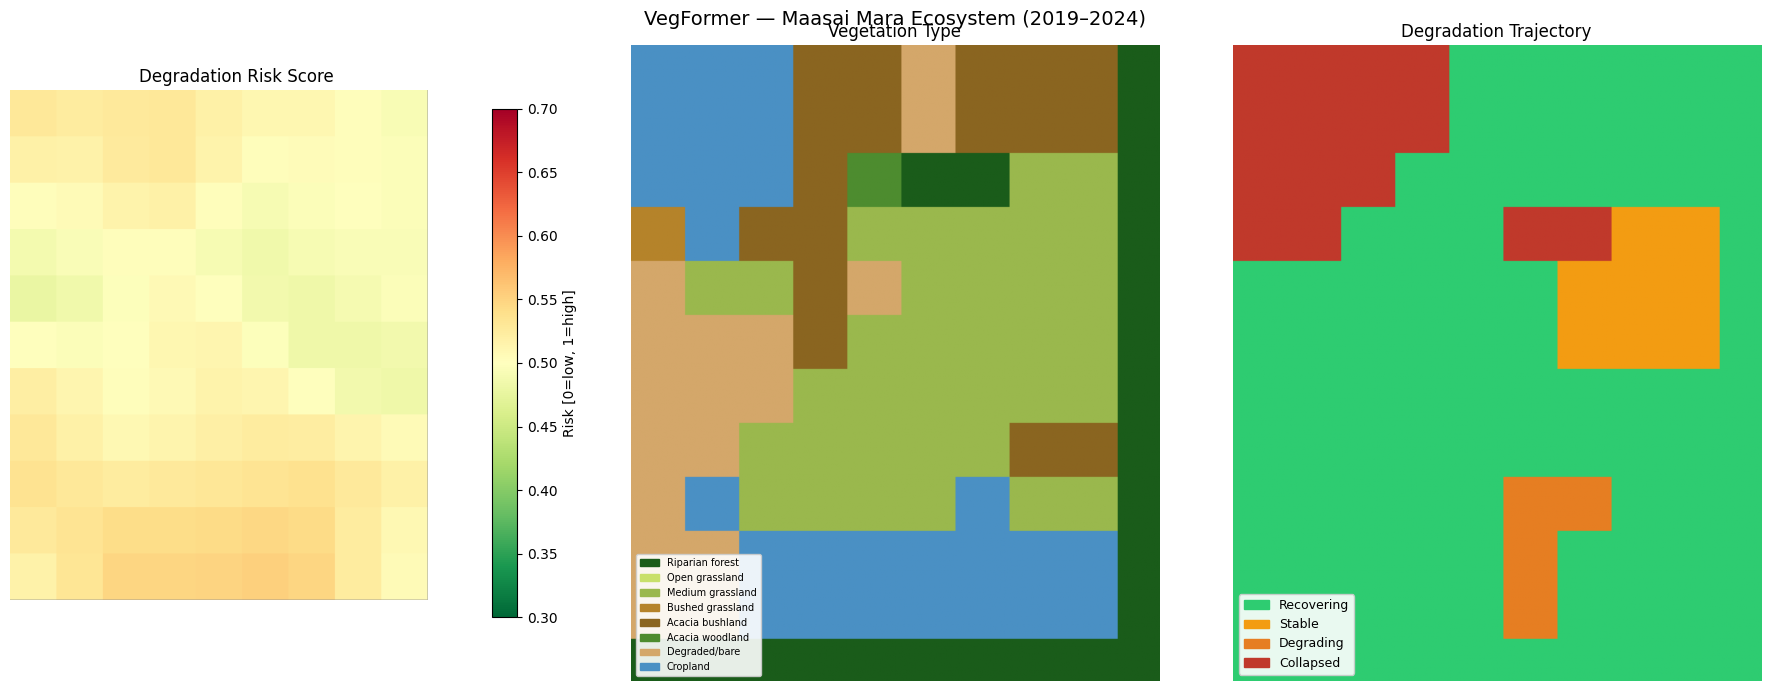

Saved: outputs/maps/vegformer_maps.png


In [4]:
# Build spatial risk and vegetation maps
# Place each patch result back into the 377x313 spatial grid
H, W       = 377, 313
PATCH_SIZE = 64
STRIDE     = 32

risk_map   = np.full((H, W), np.nan)
veg_map    = np.full((H, W), -1,    dtype=np.int32)
deg_map    = np.full((H, W), -1,    dtype=np.int32)
count_map  = np.zeros((H, W),       dtype=np.int32)

for i, (row, col) in enumerate(results['positions']):
    r, c = int(row), int(col)
    # Average overlapping patches
    existing = risk_map[r:r+PATCH_SIZE, c:c+PATCH_SIZE]
    mask     = ~np.isnan(existing)
    risk_map[r:r+PATCH_SIZE, c:c+PATCH_SIZE] = np.where(
        mask,
        (existing * count_map[r:r+PATCH_SIZE, c:c+PATCH_SIZE] +
         results['risk_scores'][i]) /
        (count_map[r:r+PATCH_SIZE, c:c+PATCH_SIZE] + 1),
        results['risk_scores'][i]
    )
    veg_map[r:r+PATCH_SIZE, c:c+PATCH_SIZE] = results['veg_types'][i]
    deg_map[r:r+PATCH_SIZE, c:c+PATCH_SIZE] = results['degradation'][i]
    count_map[r:r+PATCH_SIZE, c:c+PATCH_SIZE] += 1

print(f"Spatial maps built:")
print(f"  Valid pixels (risk):  {(~np.isnan(risk_map)).sum():,}")
print(f"  Coverage:             {(~np.isnan(risk_map)).sum()/(H*W)*100:.1f}%")
print(f"  Risk range:           {np.nanmin(risk_map):.3f} — {np.nanmax(risk_map):.3f}")

# Plot all three maps
VEG_COLORS = ['#1a5c1a','#c8e06b','#9ab84d','#b5832a',
               '#8a6520','#4d8c2f','#d4a76a','#4a90c4']
DEG_COLORS = ['#2ecc71','#f39c12','#e67e22','#c0392b']

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Risk map
im0 = axes[0].imshow(risk_map, cmap='RdYlGn_r', vmin=0.3, vmax=0.7)
axes[0].set_title('Degradation Risk Score', fontsize=12)
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], shrink=0.8, label='Risk [0=low, 1=high]')

# Vegetation type map
veg_cmap = ListedColormap(VEG_COLORS)
im1 = axes[1].imshow(veg_map, cmap=veg_cmap, vmin=0, vmax=7)
axes[1].set_title('Vegetation Type', fontsize=12)
axes[1].axis('off')
legend_veg = [Patch(color=VEG_COLORS[i], label=veg_names[i])
              for i in range(8)]
axes[1].legend(handles=legend_veg, loc='lower left',
               fontsize=7, framealpha=0.9)

# Degradation trajectory map
deg_cmap = ListedColormap(DEG_COLORS)
im2 = axes[2].imshow(deg_map, cmap=deg_cmap, vmin=0, vmax=3)
axes[2].set_title('Degradation Trajectory', fontsize=12)
axes[2].axis('off')
legend_deg = [Patch(color=DEG_COLORS[i], label=deg_names[i])
              for i in range(4)]
axes[2].legend(handles=legend_deg, loc='lower left',
               fontsize=9, framealpha=0.9)

plt.suptitle('VegFormer — Maasai Mara Ecosystem (2019–2024)', fontsize=14)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'maps/vegformer_maps.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: outputs/maps/vegformer_maps.png")

In [ ]:
#####Run UMAP on the embeddings and build the final Folium dashboard

Running UMAP on 240 patch embeddings...


C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


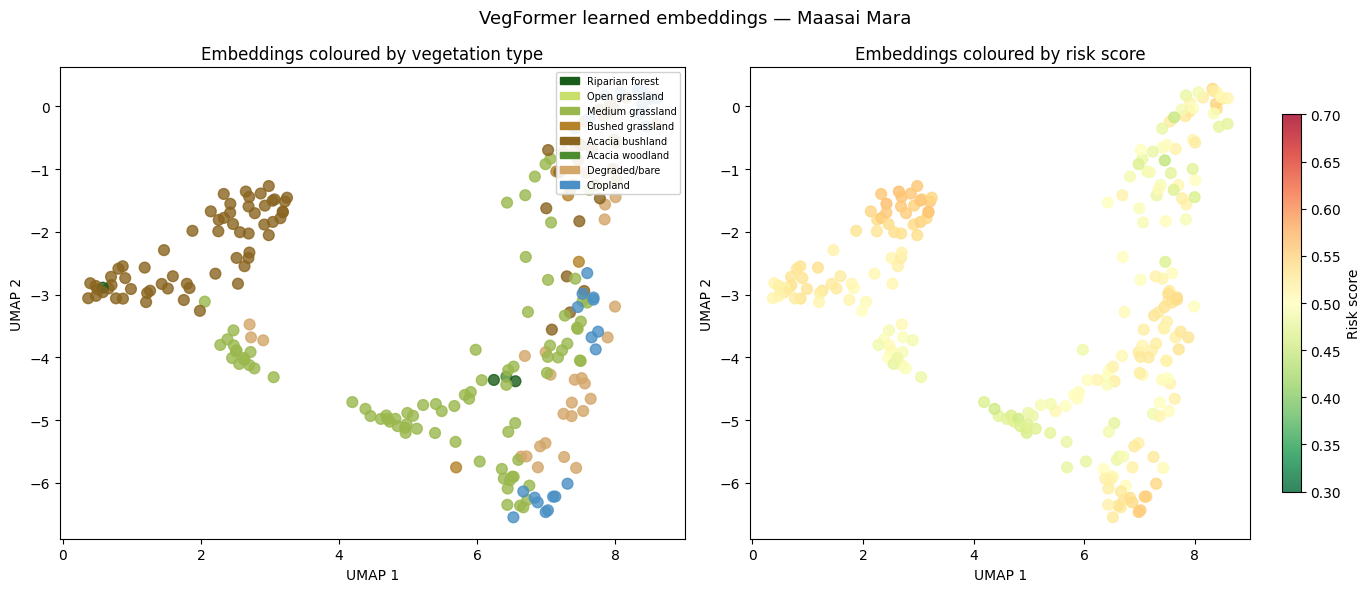

Saved: outputs/maps/umap_embeddings.png


In [5]:
# UMAP embedding visualization
from umap import UMAP

print("Running UMAP on 240 patch embeddings...")
reducer = UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
proj    = reducer.fit_transform(results['embeddings'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Coloured by vegetation type
veg_cmap = ListedColormap(VEG_COLORS)
sc1 = axes[0].scatter(proj[:, 0], proj[:, 1],
                       c=results['veg_types'],
                       cmap=veg_cmap, vmin=0, vmax=7,
                       s=60, alpha=0.8)
axes[0].set_title('Embeddings coloured by vegetation type')
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')
legend_veg = [Patch(color=VEG_COLORS[i], label=veg_names[i])
              for i in range(8)]
axes[0].legend(handles=legend_veg, fontsize=7,
               loc='upper right', framealpha=0.9)

# Coloured by risk score
sc2 = axes[1].scatter(proj[:, 0], proj[:, 1],
                       c=results['risk_scores'],
                       cmap='RdYlGn_r', vmin=0.3, vmax=0.7,
                       s=60, alpha=0.8)
axes[1].set_title('Embeddings coloured by risk score')
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')
plt.colorbar(sc2, ax=axes[1], label='Risk score', shrink=0.8)

plt.suptitle('VegFormer learned embeddings — Maasai Mara', fontsize=13)
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'maps/umap_embeddings.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/maps/umap_embeddings.png")

In [ ]:
####Build the Folium dashboard combining everythingbuild the Folium dashboard combining everything

In [9]:
# Rebuild map — title moved to bottom right
m2 = folium.Map(
    location=[-1.4061, 35.1019],
    zoom_start=9,
    tiles=None,
    control_scale=True
)

# Basemaps
folium.TileLayer(
    'https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    name='Google Satellite', attr='Google', max_zoom=20
).add_to(m2)
folium.TileLayer(
    'https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    name='Google Hybrid', attr='Google', max_zoom=20
).add_to(m2)
folium.TileLayer(
    'https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png',
    name='CartoDB Light', attr='CartoDB', max_zoom=20
).add_to(m2)
folium.TileLayer(
    'https://{s}.basemaps.cartocdn.com/dark_all/{z}/{x}/{y}{r}.png',
    name='CartoDB Dark', attr='CartoDB', max_zoom=20
).add_to(m2)
folium.TileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/World_Terrain_Base/MapServer/tile/{z}/{y}/{x}',
    name='ESRI Terrain', attr='ESRI', max_zoom=13
).add_to(m2)

# Re-add data layers
risk_group.add_to(m2)
veg_group.add_to(m2)
deg_group.add_to(m2)

# AOI boundary
folium.Polygon(
    locations=[list(reversed(c)) for c in [
        [34.8800,-1.8500],[35.0500,-1.8500],[35.2000,-1.7800],
        [35.3500,-1.6500],[35.4200,-1.5000],[35.4200,-1.1500],
        [35.3000,-1.0500],[35.1500,-1.0000],[34.9500,-1.0000],
        [34.8000,-1.0800],[34.7200,-1.2500],[34.7200,-1.5500],
        [34.7800,-1.7500],[34.8800,-1.8500]
    ]],
    color='red', weight=2, fill=False,
    tooltip='Maasai Mara Ecosystem AOI'
).add_to(m2)

# Legend — bottom left
m2.get_root().html.add_child(folium.Element(legend_html))

# Title — bottom right (no longer blocks layer control)
title_html2 = """
<div style="position:fixed;bottom:40px;right:12px;z-index:8000;
            background:rgba(255,255,255,0.95);padding:10px 16px;
            border-radius:8px;border:1px solid #ddd;
            font-family:sans-serif;font-size:13px;max-width:200px;">
    <b style="font-size:14px;">VegFormer</b><br>
    <span style="color:#555;font-size:11px;">
        Maasai Mara Ecosystem<br>
        Sentinel-1/2 · CHIRPS · 2019–2024
    </span>
</div>
"""
m2.get_root().html.add_child(folium.Element(title_html2))

# Controls — layer control top right, unobstructed
Fullscreen(position='topleft').add_to(m2)
MiniMap(toggle_display=True).add_to(m2)
folium.LayerControl(collapsed=False, position='topright').add_to(m2)

# Save
dashboard_path = str(OUTPUT_DIR / 'dashboards/vegformer_mara.html')
m2.save(dashboard_path)
print(f"Saved: {dashboard_path}")
print(f"\nLayout:")
print(f"  Top-right:    Layer control (basemaps + data layers)")
print(f"  Top-left:     Fullscreen button")
print(f"  Bottom-left:  Legend")
print(f"  Bottom-right: VegFormer title")
print(f"  Bottom-right: MiniMap")

Saved: C:\vegformer\outputs\dashboards\vegformer_mara.html

Layout:
  Top-right:    Layer control (basemaps + data layers)
  Top-left:     Fullscreen button
  Bottom-left:  Legend
  Bottom-right: VegFormer title
  Bottom-right: MiniMap
